#Module End Assignment “Social Media Engagement Analytics”

##Assignment Tasks:

###❖ Task 1 — Data Import & Setup
####○ Import CSV using Pandas
####○ Check/convert data types
####○ Convert date columns to datetime

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
import plotly.express as px

df = pd.read_csv("/content/drive/MyDrive/Python/capstone project dataset/social_media_engagement_5000.csv")

In [ ]:
df


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [ ]:
from numpy import dtypes
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


In [ ]:
#Convert date column to datetime
df["posted_at"] = pd.to_datetime(
    df["posted_at"], errors="coerce"
)


/tmp/ipykernel_1983/2812585658.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["posted_at"] = pd.to_datetime(


##❖ Task 2 — Data Cleaning
###● Cleaning Missing Data


### Detect missing values (isnull(), isna())
### Handle using: dropna(), fillna(), median/mode, forward/backward-fill
### Duplicate Handling- Identify & remove duplicates
### Data Formatting
####■ Fix incorrect data types
####■ Standardize categories (e.g., gender labels)



In [ ]:
#■ Detect missing values (isnull(), isna())
# Check missing values using isnull()
print(df.isnull().sum())

# Check missing values using isna()
print(df.isna().sum())

# Display only columns with missing values
print("\nColumns with missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Calculate missing value percentages
print("\nMissing value percentage:")
print((df.isnull().mean() * 100).round(2))

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

Columns with missing values:
age          150
gender       15

In [ ]:
#■ Handle using: dropna(), fillna(), median/mode, forward/backward-fill

# Remove exact duplicate rows
df = df.drop_duplicates()

# Remove rows with missing critical fields
df = df.dropna(subset=["posted_at", "post_id"])

# Fill missing numerical values using the median
numeric_cols = [
    "age", "likes", "comments", "shares",
    "watch_time_sec", "impression_count",
    "follower_count", "engagement_rate"
]

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values using the mode
categorical_cols = [
    "gender", "country", "post_type",
    "post_category", "is_verified",
    "device_type", "sentiment"
]

for col in categorical_cols:
    if df[col].isnull().any():
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values.iloc[0])

# Fill missing hashtag text
df["hashtags"] = df["hashtags"].fillna("")

print("Missing values handled.")
print(df.isnull().sum())

Missing values handled.
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [ ]:
#Standardize categories and correct unrealistic values
text_cols = [
    "gender", "country", "post_type",
    "post_category", "device_type", "sentiment"
]

for col in text_cols:
    df[col] = df[col].astype("string").str.strip().str.lower()

# Standardize common gender labels
df["gender"] = df["gender"].replace({
    "m": "male",
    "man": "male",
    "f": "female",
    "woman": "female",
    "others": "other"
})

# Clean sentiment labels
df["sentiment"] = df["sentiment"].replace({
    "pos": "positive",
    "neg": "negative",
    "neu": "neutral"
})

# Correct unrealistic values by replacing invalid values with NaN
# and filling them with the median
valid_ranges = {
    "age": (13, 100),
    "likes": (0, np.inf),
    "comments": (0, np.inf),
    "shares": (0, np.inf),
    "watch_time_sec": (0, np.inf),
    "impression_count": (0, np.inf),
    "follower_count": (0, np.inf),
    "engagement_rate": (0, np.inf)
}

for col, (lower, upper) in valid_ranges.items():
    invalid = (df[col] < lower) | (df[col] > upper)
    df.loc[invalid, col] = np.nan

    if df[col].notna().any():
        df[col] = df[col].fillna(df[col].median())

# Convert count fields to integer where appropriate
count_cols = [
    "likes", "comments", "shares",
    "watch_time_sec", "impression_count", "follower_count"
]

for col in count_cols:
    df[col] = df[col].round().astype("int64")

print("Categories standardized and invalid values checked.")

Categories standardized and invalid values checked.


In [ ]:
#Extract hashtag count
# Count hashtags in each post
df["hashtag_count"] = df["hashtags"].apply(
    lambda x: len(re.findall(r"#\w+", str(x)))
)

# Display hashtag counts
print(df[["hashtags", "hashtag_count"]].head(10))

                  hashtags  hashtag_count
0    #foodie #travel #love              3
1                 #fitness              1
2                  #foodie              1
3      #music #foodie #fun              3
4                  #travel              1
5                 #fitness              1
6                   #music              1
7  #travel #music #fitness              3
8     #music #fun #fitness              3
9         #lifestyle #love              2


In [ ]:
#Forward-fill and backward-fill example
# Example: fill remaining missing values in a time-ordered series
df = df.sort_values("posted_at").copy()

# Example only for a field where nearby values are meaningful
# df["some_time_series_column"] = (
#     df["some_time_series_column"].ffill().bfill()
# )

print("Data cleaning completed.")

Data cleaning completed.


###❖ Task 3 — Data Exploration using Pandas

In [ ]:
# First five rows
print(df.head())

# Last five rows
print(df.tail())

# Number of rows and columns
print("Shape:", df.shape)

# Column names
print("Columns:", df.columns.tolist())

# Dataset information
df.info()

# Data types
print(df.dtypes)

# Summary statistics
print(df.describe())

      user_id   age  gender    country  post_id post_type post_category  \
3876    65745  20.0  female        usa   716149     video     education   
3944    73232  58.0    male     brazil   763662     video     lifestyle   
2891    16629  50.0  female     france   916929     video          tech   
1044    19446  54.0  female      india   106028      reel       fashion   
570     97508  48.0    male  australia   155313      text     lifestyle   

      likes  comments  shares  watch_time_sec  impression_count  posted_at  \
3876   5780      1926    1536            4193             11037 2022-01-01   
3944  10924       992    1461            2174             11361 2022-01-01   
2891  19873       243    1918            6385              1334 2022-01-01   
1044   9723       248    1817            5305             92434 2022-01-01   
570    4000      2900     714            1490              8166 2022-01-01   

      follower_count  is_verified device_type sentiment              hashtags  \

In [ ]:
#Analyze categorical distributions
# Gender distribution
print(df["gender"].value_counts())

# Unique post types
print(df["post_type"].unique())

# Number of unique countries
print("Unique countries:", df["country"].nunique())

# Sentiment distribution
print(df["sentiment"].value_counts())

# Device type distribution
print(df["device_type"].value_counts())

gender
male      1849
other     1581
female    1570
Name: count, dtype: Int64
<StringArray>
['video', 'reel', 'text', 'image']
Length: 4, dtype: string
Unique countries: 10
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: Int64
device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: Int64


In [ ]:
#Correlation matrix
numeric_cols = [
    "age", "likes", "comments", "shares",
    "watch_time_sec", "impression_count",
    "follower_count", "engagement_rate",
    "hashtag_count"
]

correlation_matrix = df[numeric_cols].corr()

print(correlation_matrix.round(2))

                   age  likes  comments  shares  watch_time_sec  \
age               1.00  -0.04     -0.01    0.01            0.01   
likes            -0.04   1.00     -0.02    0.00            0.01   
comments         -0.01  -0.02      1.00    0.01           -0.02   
shares            0.01   0.00      0.01    1.00            0.01   
watch_time_sec    0.01   0.01     -0.02    0.01            1.00   
impression_count  0.01   0.01     -0.01   -0.01           -0.00   
follower_count   -0.02  -0.02     -0.01   -0.01            0.00   
engagement_rate   0.01   0.09      0.00    0.02           -0.00   
hashtag_count     0.01  -0.00     -0.02    0.01           -0.02   

                  impression_count  follower_count  engagement_rate  \
age                           0.01           -0.02             0.01   
likes                         0.01           -0.02             0.09   
comments                     -0.01           -0.01             0.00   
shares                       -0.01           

In [ ]:
#Groupby analysis
# Average likes by post type
print(
    df.groupby("post_type")["likes"]
      .mean()
      .sort_values(ascending=False)
)

# Average engagement rate by post category
print(
    df.groupby("post_category")["engagement_rate"]
      .mean()
      .sort_values(ascending=False)
)

# Average impressions by country
print(
    df.groupby("country")["impression_count"]
      .mean()
      .sort_values(ascending=False)
)

# Summary by sentiment
print(
    df.groupby("sentiment")[
        ["likes", "comments", "shares", "engagement_rate"]
    ].mean().round(2)
)

post_type
video    10188.613878
image    10104.878107
text     10100.163855
reel     10037.819953
Name: likes, dtype: float64
post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64
country
india        52462.386916
france       51727.673387
usa          51263.872255
uk           51119.393509
japan        49616.135593
brazil       49193.174603
uae          48928.413519
canada       48703.150097
germany      48605.406122
australia    48346.383367
Name: impression_count, dtype: float64
              likes  comments   shares  engagement_rate
sentiment                                              
negative   10208.11   1516.09  1007.31             1.04
neutral     9923.21   1528.40   996.57             0.99
positive   10180.08   1480.65  1005.09             0.92


###❖ Task 4 — Data Wrangling

In [ ]:
# Calculate total engagement actions
df["engagement_score"] = (
    df["likes"] + df["comments"] + df["shares"]
)

# Calculate log-transformed metrics
df["log_likes"] = np.log1p(df["likes"])
df["log_impressions"] = np.log1p(df["impression_count"])
df["log_followers"] = np.log1p(df["follower_count"])

# Extract day, month, and weekday
df["day"] = df["posted_at"].dt.day
df["month"] = df["posted_at"].dt.month
df["weekday"] = df["posted_at"].dt.day_name()

print(df[[
    "engagement_score", "hashtag_count",
    "log_likes", "weekday"
]].head())

      engagement_score  hashtag_count  log_likes   weekday
3876              9242              1   8.662332  Saturday
3944             13377              1   9.298809  Saturday
2891             22034              3   9.897168  Saturday
1044             11788              1   9.182352  Saturday
570               7614              2   8.294300  Saturday


In [ ]:
#Groupby summaries
# Summary by post type
post_type_summary = df.groupby("post_type").agg(
    average_likes=("likes", "mean"),
    average_comments=("comments", "mean"),
    average_shares=("shares", "mean"),
    average_engagement=("engagement_rate", "mean"),
    total_posts=("post_id", "count")
)

print(post_type_summary.round(2))

# Summary by country
country_summary = df.groupby("country").agg(
    average_engagement=("engagement_rate", "mean"),
    average_impressions=("impression_count", "mean"),
    total_posts=("post_id", "count")
)

print(country_summary.sort_values(
    "average_engagement", ascending=False
).round(2))

# Summary by sentiment
sentiment_summary = df.groupby("sentiment").agg(
    average_likes=("likes", "mean"),
    average_comments=("comments", "mean"),
    average_shares=("shares", "mean"),
    average_engagement=("engagement_rate", "mean")
)

print(sentiment_summary.round(2))

           average_likes  average_comments  average_shares  \
post_type                                                    
image           10104.88           1525.24         1019.29   
reel            10037.82           1504.19          982.04   
text            10100.16           1499.11         1013.99   
video           10188.61           1479.16          996.83   

           average_engagement  total_posts  
post_type                                   
image                    0.90         1247  
reel                     0.78         1283  
text                     1.06         1245  
video                    1.12         1225  
           average_engagement  average_impressions  total_posts
country                                                        
brazil                   1.54             49193.17          504
australia                1.32             48346.38          493
france                   1.15             51727.67          496
uae                      1.11        

In [ ]:
#Merge
# Create a country summary
country_avg = df.groupby("country", as_index=False).agg(
    country_avg_engagement=("engagement_rate", "mean")
)

# Merge the summary back into the main dataset
df = df.merge(country_avg, on="country", how="left")

print(df[[
    "country", "engagement_rate",
    "country_avg_engagement"
]].head())

     country  engagement_rate  country_avg_engagement
0        usa         0.837365                0.576580
1     brazil         1.177449                1.540704
2     france        16.517241                1.146402
3      india         0.127529                0.655005
4  australia         0.932403                1.324339


###❖ Task 5 — Statistical Analysis

In [ ]:
stats_cols = [
    "likes", "comments", "shares",
    "watch_time_sec", "engagement_rate",
    "follower_count"
]

# Descriptive statistics
print(df[stats_cols].describe())

# Mean
print("\nMean:")
print(df[stats_cols].mean())

# Median
print("\nMedian:")
print(df[stats_cols].median())

# Mode
print("\nMode:")
print(df[stats_cols].mode().iloc[0])

# Standard deviation
print("\nStandard Deviation:")
print(df[stats_cols].std())

# Variance
print("\nVariance:")
print(df[stats_cols].var())

# Percentiles
print("\nPercentiles:")
print(df[stats_cols].quantile([0.25, 0.50, 0.75, 0.90, 0.95]))

# Skewness
print("\nSkewness:")
print(df[stats_cols].skew())

# Kurtosis
print("\nKurtosis:")
print(df[stats_cols].kurt())

              likes     comments     shares  watch_time_sec  engagement_rate  \
count   5000.000000  5000.000000  5000.0000     5000.000000      5000.000000   
mean   10107.012400  1502.039800  1002.9106     4014.503200         0.964356   
std     5702.293014   856.393312   570.8552     2308.096459         5.318029   
min       10.000000     0.000000     0.0000        0.000000         0.006363   
25%     5235.000000   792.000000   511.0000     2017.750000         0.145781   
50%    10106.000000  1497.000000  1012.0000     4034.500000         0.253896   
75%    14959.000000  2235.250000  1483.0000     6020.250000         0.504794   
max    19998.000000  2999.000000  1999.0000     7998.000000       191.504348   

       follower_count  
count     5000.000000  
mean    393698.224800  
std     230927.884535  
min         87.000000  
25%     194480.000000  
50%     388982.000000  
75%     589744.250000  
max     799533.000000  

Mean:
likes               10107.012400
comments             15

###Task 6 — Data Visualization

####● Matplotlib
#####○ Scatter: likes vs impressions
#####○ Line: daily engagement trend
#####○ Bar: posts by category
#####○ Pie: gender distribution
#####○ Histogram: age
#####○ Box: engagement rate

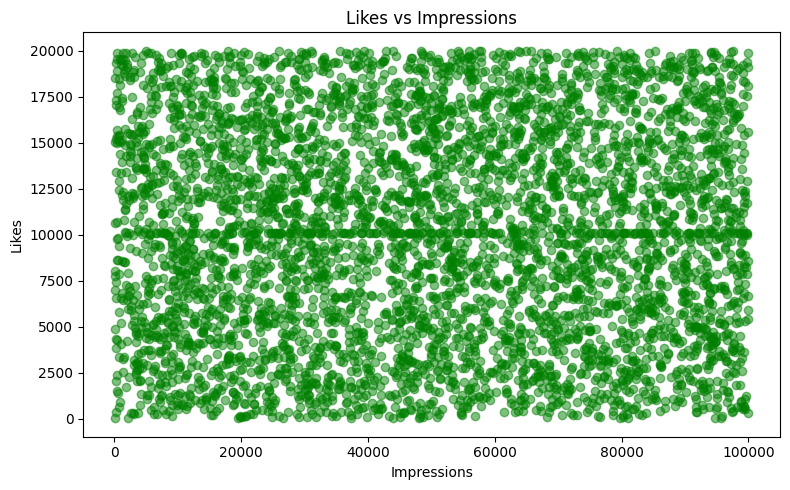

In [ ]:
#ScatterPlot
plt.figure(figsize=(8, 5))
plt.scatter(df["impression_count"], df["likes"], color='green',alpha=0.5)

plt.title("Likes vs Impressions")
plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.tight_layout()
plt.show()

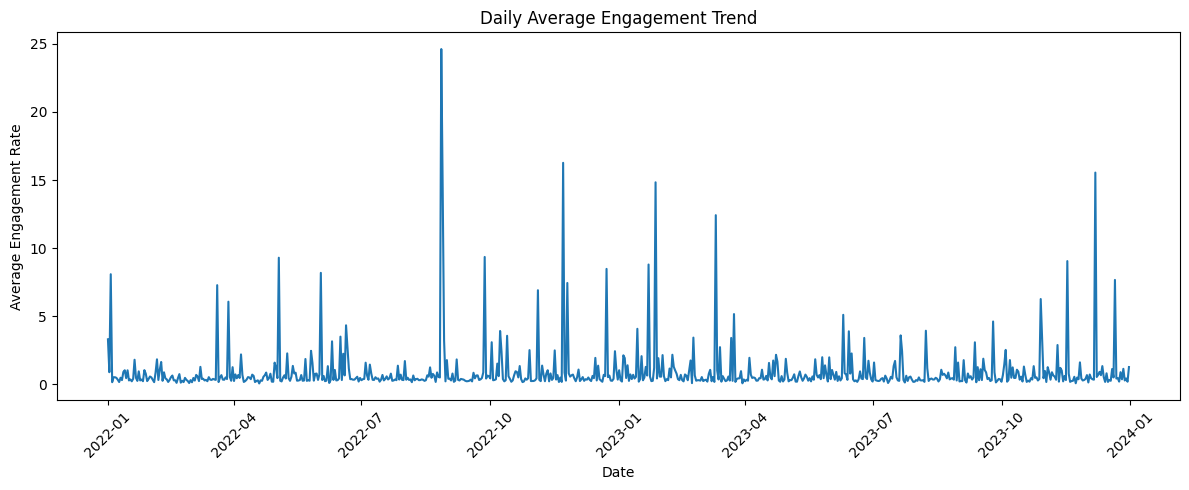

In [ ]:
#Line chart
daily_engagement = (
    df.groupby(df["posted_at"].dt.date)["engagement_rate"]
      .mean()
)

plt.figure(figsize=(12, 5))
plt.plot(daily_engagement.index,daily_engagement.values)

plt.title("Daily Average Engagement Trend")
plt.xlabel("Date")
plt.ylabel("Average Engagement Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

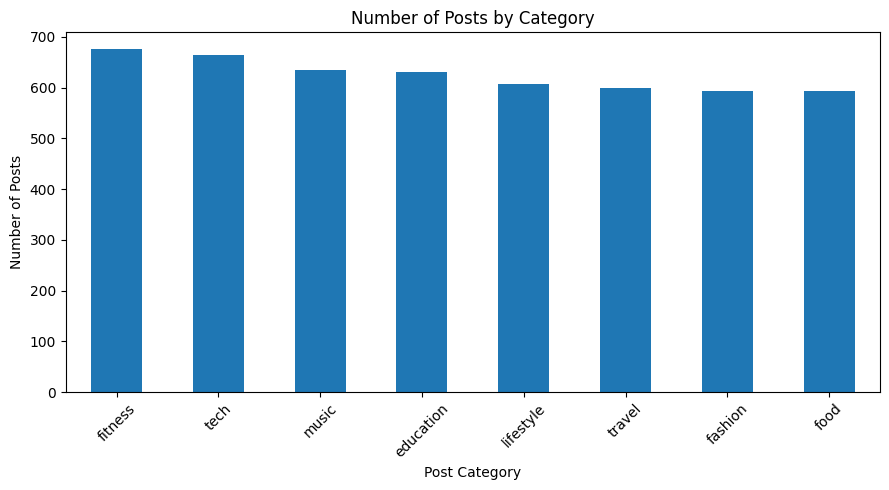

In [ ]:
#Bar chart
category_counts = df["post_category"].value_counts()

plt.figure(figsize=(9, 5))
category_counts.plot(kind="bar")

plt.title("Number of Posts by Category")
plt.xlabel("Post Category")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

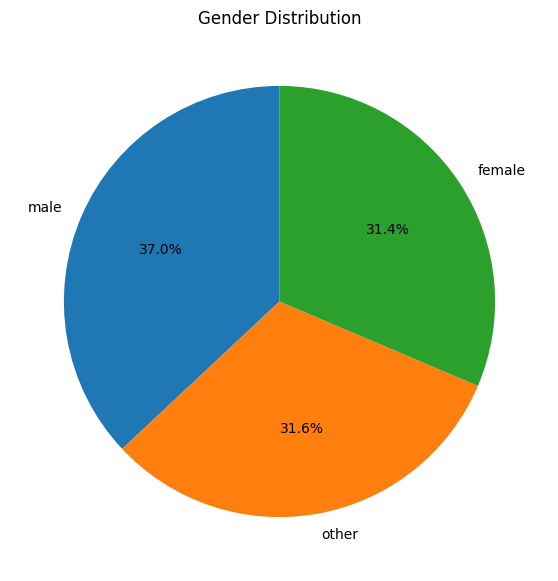

In [ ]:
#Pie Chart
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Gender Distribution")
plt.show()

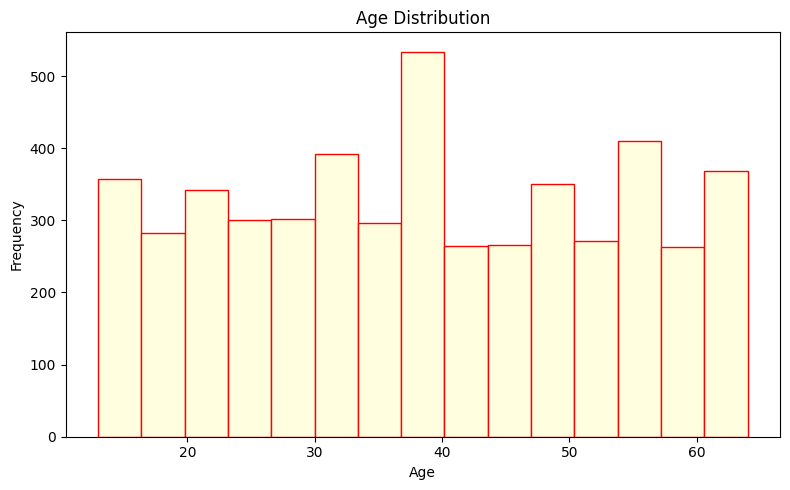

In [ ]:
#Histogram
plt.figure(figsize=(8, 5))
plt.hist(df["age"], bins=15, color='lightyellow',
    edgecolor='red')

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

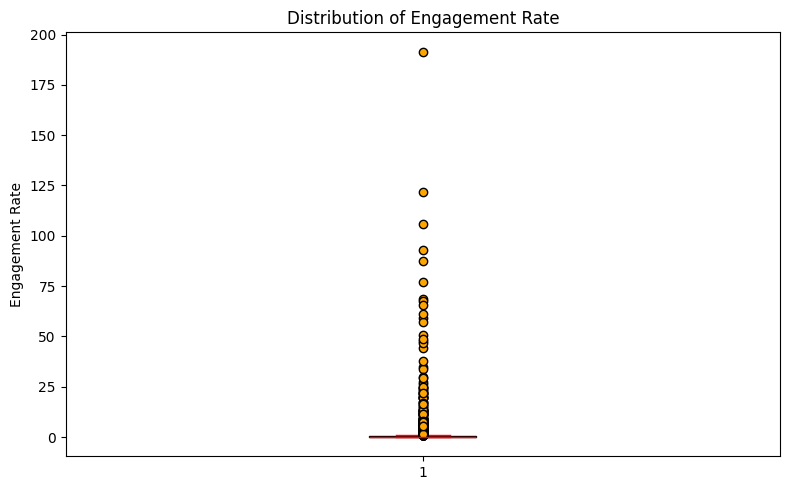

In [ ]:
#Box Plot
plt.figure(figsize=(8, 5))
#plt.boxplot(df["engagement_rate"].dropna())
plt.boxplot(df["engagement_rate"].dropna(),

            patch_artist   = True,
            boxprops       = dict(facecolor='lightgreen',color='black'),
            medianprops  = dict(color='red'),
            whiskerprops  = dict(color='yellow'),
            capprops       = dict(color='red'),
            flierprops       = dict(marker='o',markerfacecolor='orange'))

plt.title("Distribution of Engagement Rate")
plt.ylabel("Engagement Rate")
plt.tight_layout()
plt.show()

####● Seaborn
#####○ Count plot: post type
#####○ Bar plot: avg likes by category
#####○ Violin: followers vs sentiment
#####○ Pair plot: numeric features
#####○ Heatmap: correlation matrix
#####○ Swarm plot: engagement vs device

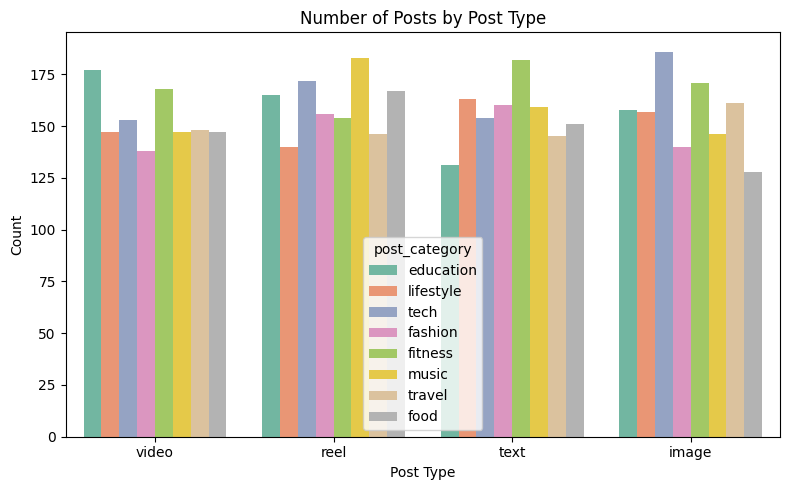

In [ ]:
#Count Plot
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="post_type",hue="post_category",       # additional category   ## male Female

    palette="Set2")

plt.title("Number of Posts by Post Type")
plt.xlabel("Post Type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

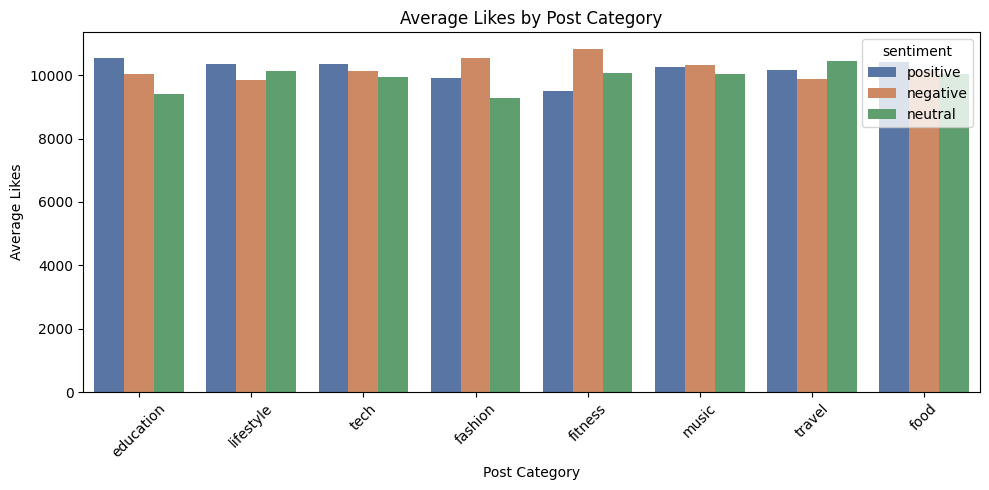

In [ ]:
#Bar Plot
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="post_category",
    y="likes",
    hue="sentiment",
    palette="deep",
    errorbar=None
)

plt.title("Average Likes by Post Category")
plt.xlabel("Post Category")
plt.ylabel("Average Likes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

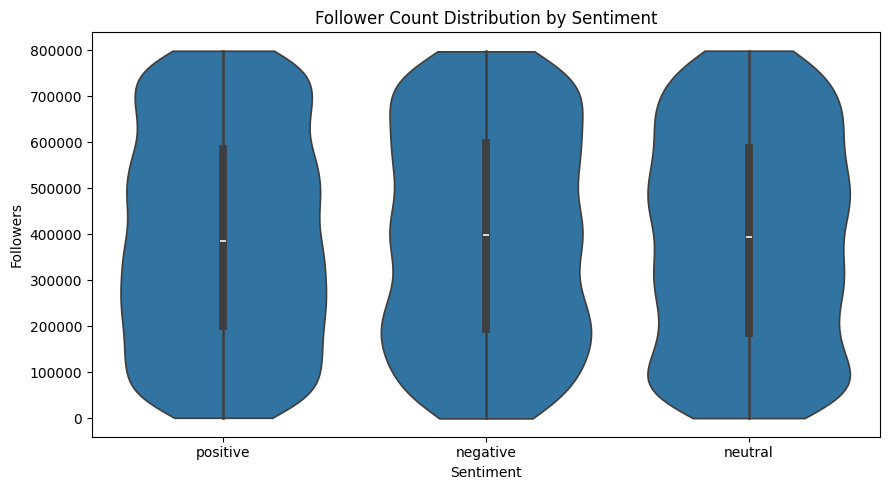

In [ ]:
#Violin plot
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df,
    x="sentiment",
    y="follower_count",
    cut=0,

)

plt.title("Follower Count Distribution by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Followers")
plt.tight_layout()
plt.show()

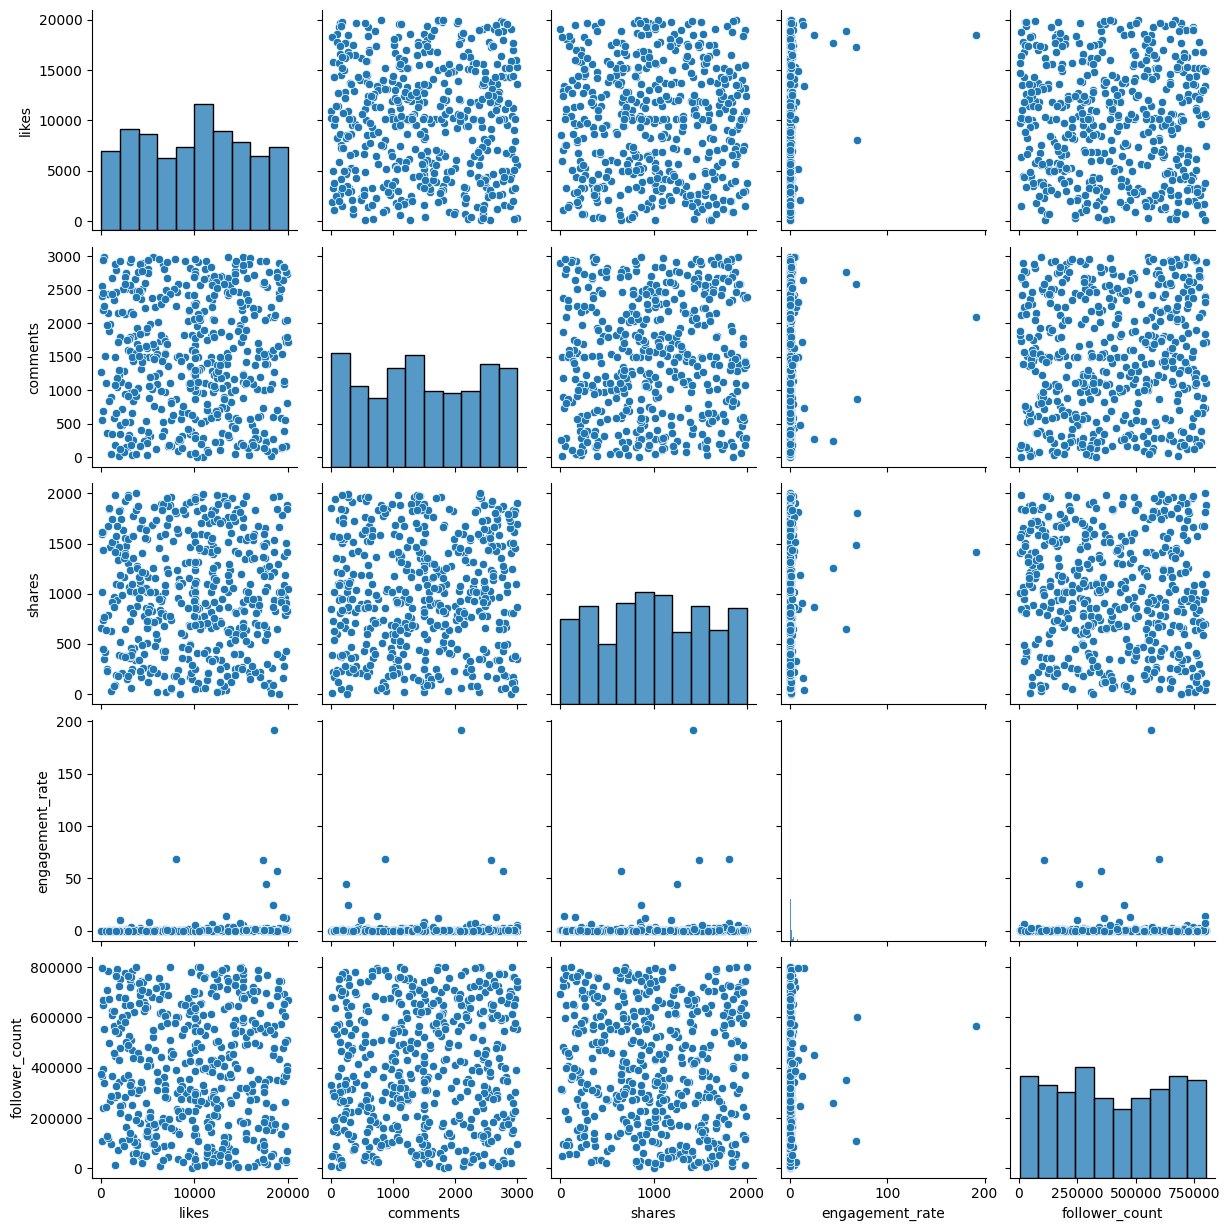

In [ ]:
#Pair plot
pair_cols = [
    "likes", "comments", "shares",
    "engagement_rate", "follower_count"
]

# Sample 500 rows to improve plotting speed
pair_df = df[pair_cols].dropna().sample(
    n=min(500, len(df)),
    random_state=42
)

sns.pairplot(pair_df, diag_kind="hist")
plt.show()

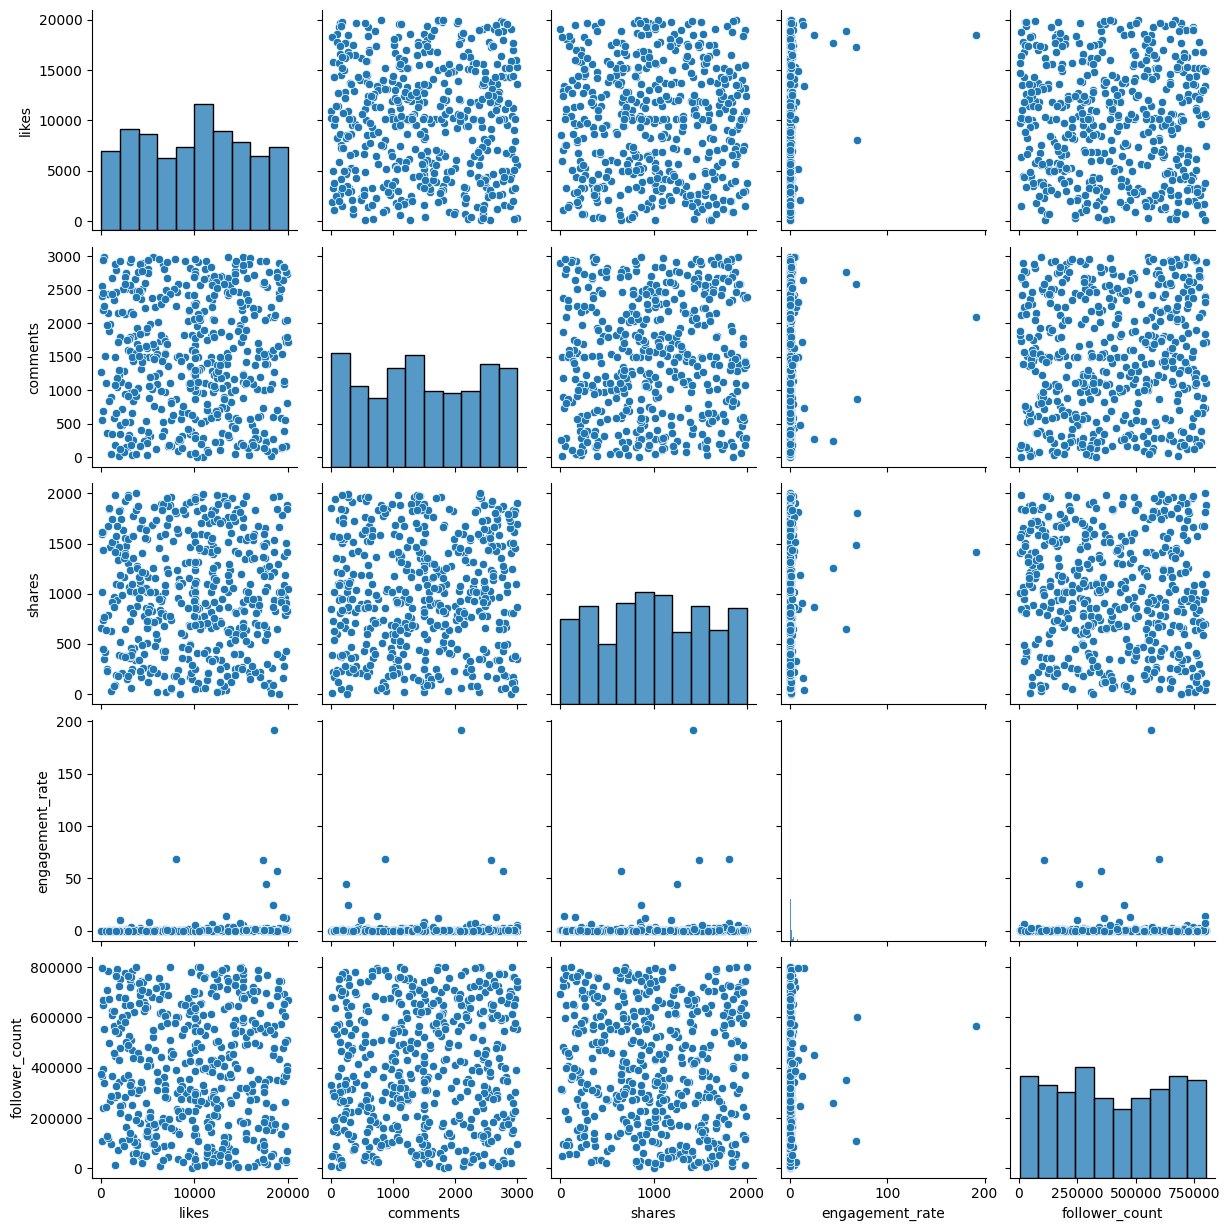

In [ ]:
#Heat Map
pair_cols = [
    "likes", "comments", "shares",
    "engagement_rate", "follower_count"
]

# Sample 500 rows to improve plotting speed
pair_df = df[pair_cols].dropna().sample(
    n=min(500, len(df)),
    random_state=42
)

sns.pairplot(pair_df, diag_kind="hist")
plt.show()


/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 50.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 49.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 52.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 55.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 54.2% of the points cannot be plac

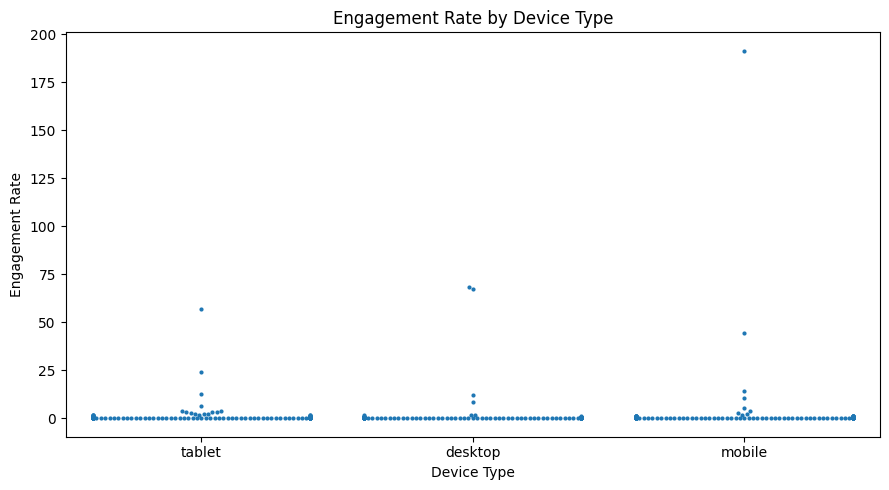

In [ ]:
#Swarm plot:
# Use a sample to avoid overcrowding and slow rendering
swarm_df = df.sample(
    n=min(400, len(df)),
    random_state=42
)

plt.figure(figsize=(9, 5))

sns.swarmplot(
    data=swarm_df,
    x="device_type",
    y="engagement_rate",
    size=3
)

plt.title("Engagement Rate by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Engagement Rate")
plt.tight_layout()
plt.show()

###C. Plotly — Interactive visualization
####Interactive scatter chart

In [ ]:
#Interactive scatter chart
fig = px.scatter(
    df,
    x="impression_count",
    y="likes",
    color="post_type",
    size="comments",
    hover_data=[
        "country", "post_category",
        "sentiment", "engagement_rate"
    ],
    title="Interactive Social Media Engagement Analysis",
    labels={
        "impression_count": "Impressions",
        "likes": "Likes",
        "comments": "Comments"
    }
)

fig.show()